Изучаем данные из датасета

Подключаем датасет и настраиваем графики

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Настройки для графиков
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#Загружаем данные
data = pd.read_csv('Electric_Vehicle_Population_Data.csv')

print("\nРазмер: ", data.shape)
print("Колонки")
print(data.columns.tolist())


Размер:  (112634, 17)
Колонки
['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Base MSRP', 'Legislative District', 'DOL Vehicle ID', 'Vehicle Location', 'Electric Utility', '2020 Census Tract']


Первые 5 строк датасета

In [118]:
#Первые 5 строк
print("Первые пять строк: ")
print(data.head())


Первые пять строк: 
   VIN (1-10)     County      City State  Postal Code  Model Year       Make  \
0  JTMEB3FV6N     Monroe  Key West    FL        33040        2022     TOYOTA   
1  1G1RD6E45D      Clark  Laughlin    NV        89029        2013  CHEVROLET   
2  JN1AZ0CP8B     Yakima    Yakima    WA        98901        2011     NISSAN   
3  1G1FW6S08H     Skagit  Concrete    WA        98237        2017  CHEVROLET   
4  3FA6P0SU1K  Snohomish   Everett    WA        98201        2019       FORD   

        Model                   Electric Vehicle Type  \
0  RAV4 PRIME  Plug-in Hybrid Electric Vehicle (PHEV)   
1        VOLT  Plug-in Hybrid Electric Vehicle (PHEV)   
2        LEAF          Battery Electric Vehicle (BEV)   
3     BOLT EV          Battery Electric Vehicle (BEV)   
4      FUSION  Plug-in Hybrid Electric Vehicle (PHEV)   

  Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0           Clean Alternative Fuel Vehicle Eligible              42   
1           Cl

Пропуски в датасете

In [119]:
print("Пропуски в датасете: ")
print(data.isnull().sum())
print("\nВсего попусков: ")
print(data.isnull().sum().sum())

Пропуски в датасете: 
VIN (1-10)                                             0
County                                                 0
City                                                   0
State                                                  0
Postal Code                                            0
Model Year                                             0
Make                                                   0
Model                                                 20
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         0
Base MSRP                                              0
Legislative District                                 286
DOL Vehicle ID                                         0
Vehicle Location                                      24
Electric Utility                                     443
2020 Census Tract                                      0
dtype: in

Статистика по числовым значениям и уникальные значения

In [120]:
print("Статистика по числовым значениям: ")
display(data.describe())

print("\n\nУникальные значения в датасете: ")
for stroki_unique in data.select_dtypes(include='str').columns:
    print(f"\n{stroki_unique} ({data[stroki_unique].nunique()} уникальных):")

Статистика по числовым значениям: 


,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,112634.000000,112634.000000,112634.000000,112634.000000,112348.000000,1.126340e+05,1.126340e+05
mean,98156.226850,2019.003365,87.812987,1793.439681,29.805604,1.994567e+08,5.296650e+10
std,2648.733064,2.892364,102.334216,10783.753486,14.700545,9.398427e+07,1.699104e+09
min,1730.000000,1997.000000,0.000000,0.000000,1.000000,4.777000e+03,1.101001e+09
25%,98052.000000,2017.000000,0.000000,0.000000,18.000000,1.484142e+08,5.303301e+10
50%,98119.000000,2020.000000,32.000000,0.000000,34.000000,1.923896e+08,5.303303e+10
75%,98370.000000,2022.000000,208.000000,0.000000,43.000000,2.191899e+08,5.305307e+10
max,99701.000000,2023.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.603300e+10




Уникальные значения в датасете: 

VIN (1-10) (7548 уникальных):

County (165 уникальных):

City (629 уникальных):

State (45 уникальных):

Make (34 уникальных):

Model (114 уникальных):

Electric Vehicle Type (2 уникальных):

Clean Alternative Fuel Vehicle (CAFV) Eligibility (3 уникальных):

Vehicle Location (758 уникальных):

Electric Utility (73 уникальных):


Визуализация значимых признаков

Гистограммы для числовых колонок

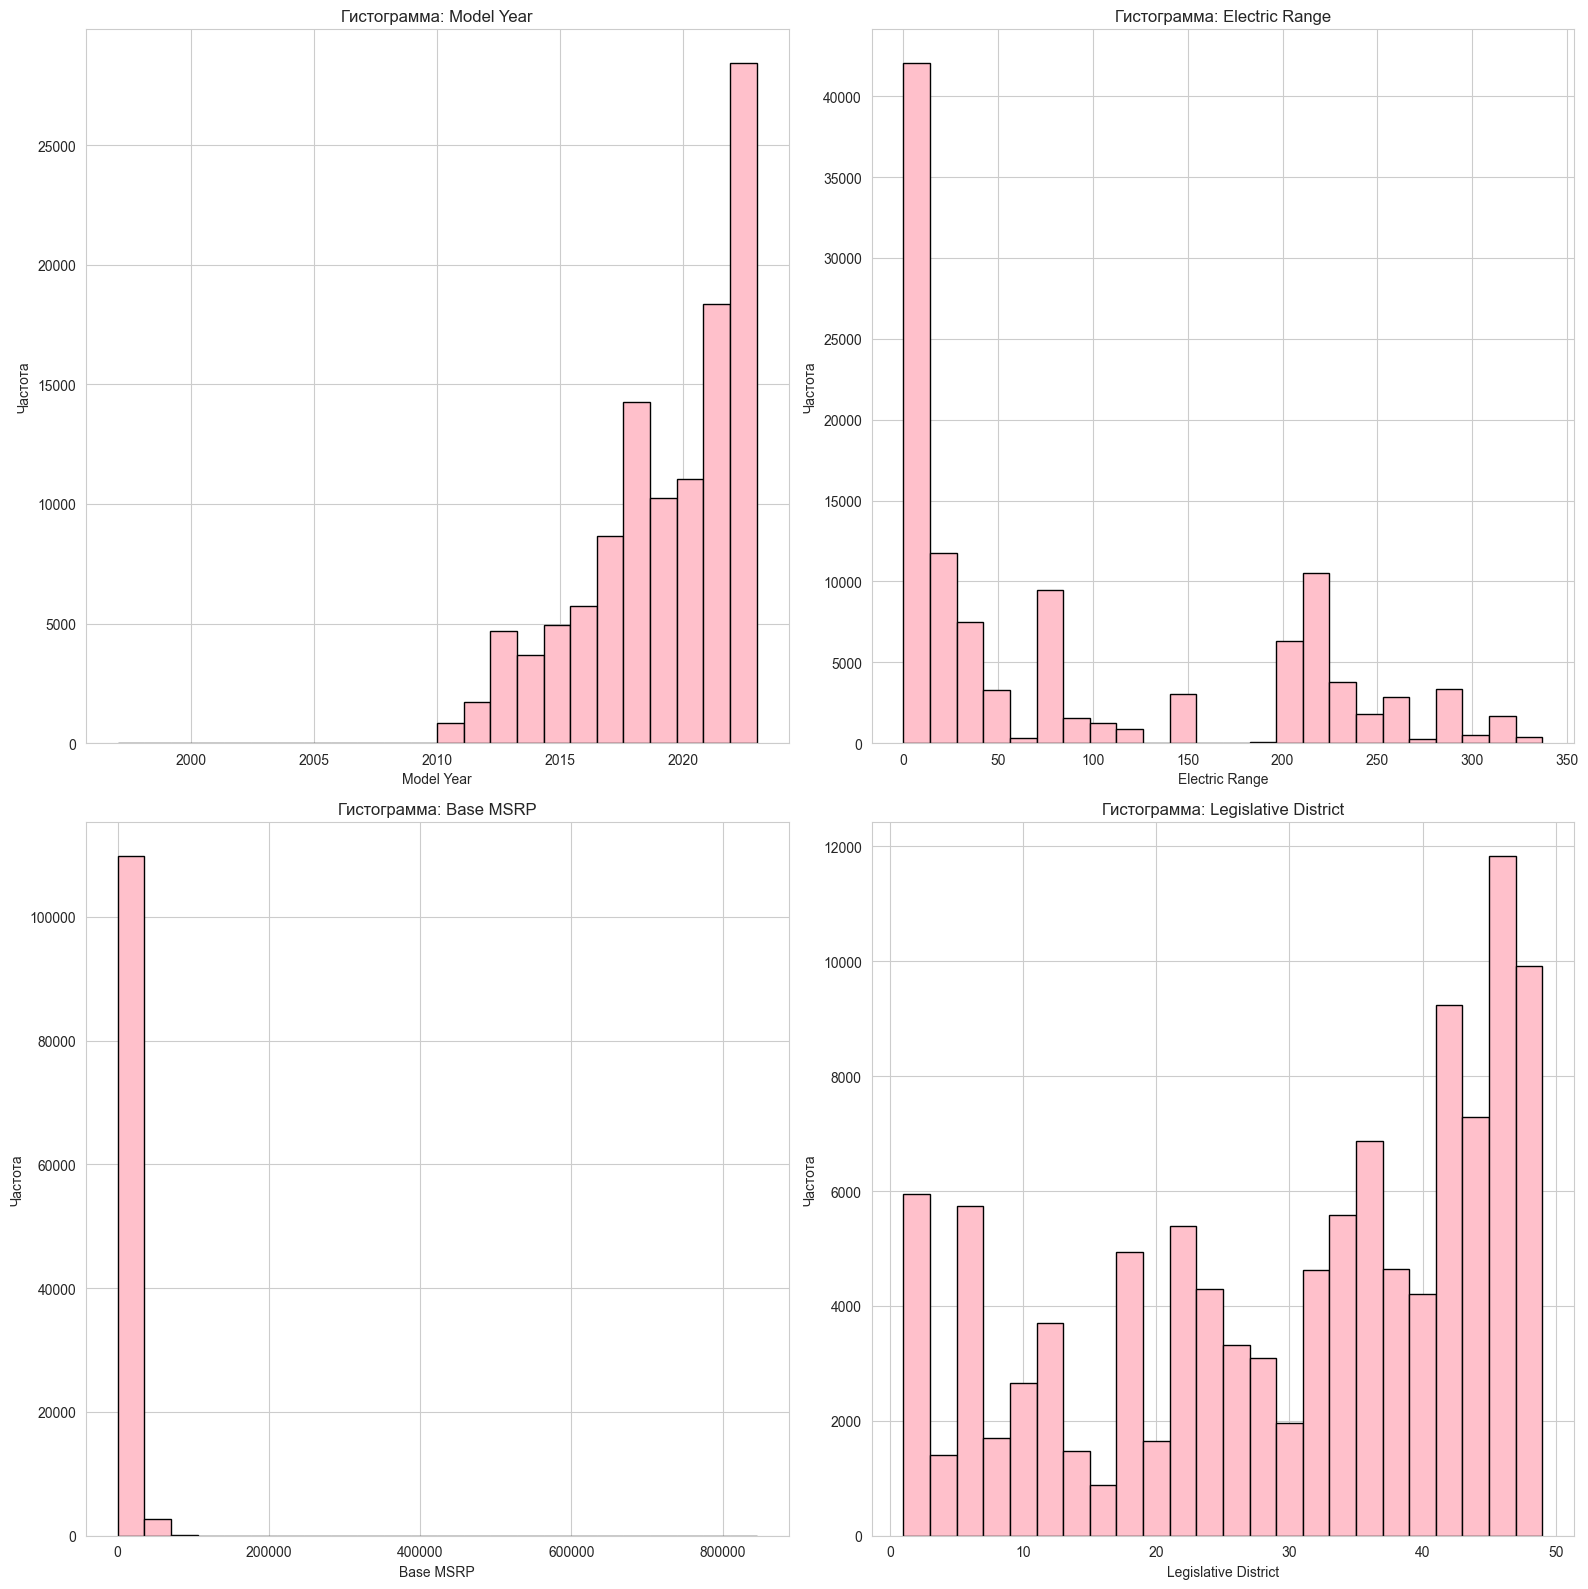

In [121]:
numeric_cols = ['Model Year', 'Electric Range', 'Base MSRP', 'Legislative District']

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten() # flatten - превращает двумерный массив в одномерный

for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col].dropna(), bins=24, edgecolor='black', color='pink')
    axes[i].set_title(f'Гистограмма: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

Ящик с усами по электрическому диапазону и типу автомобиля

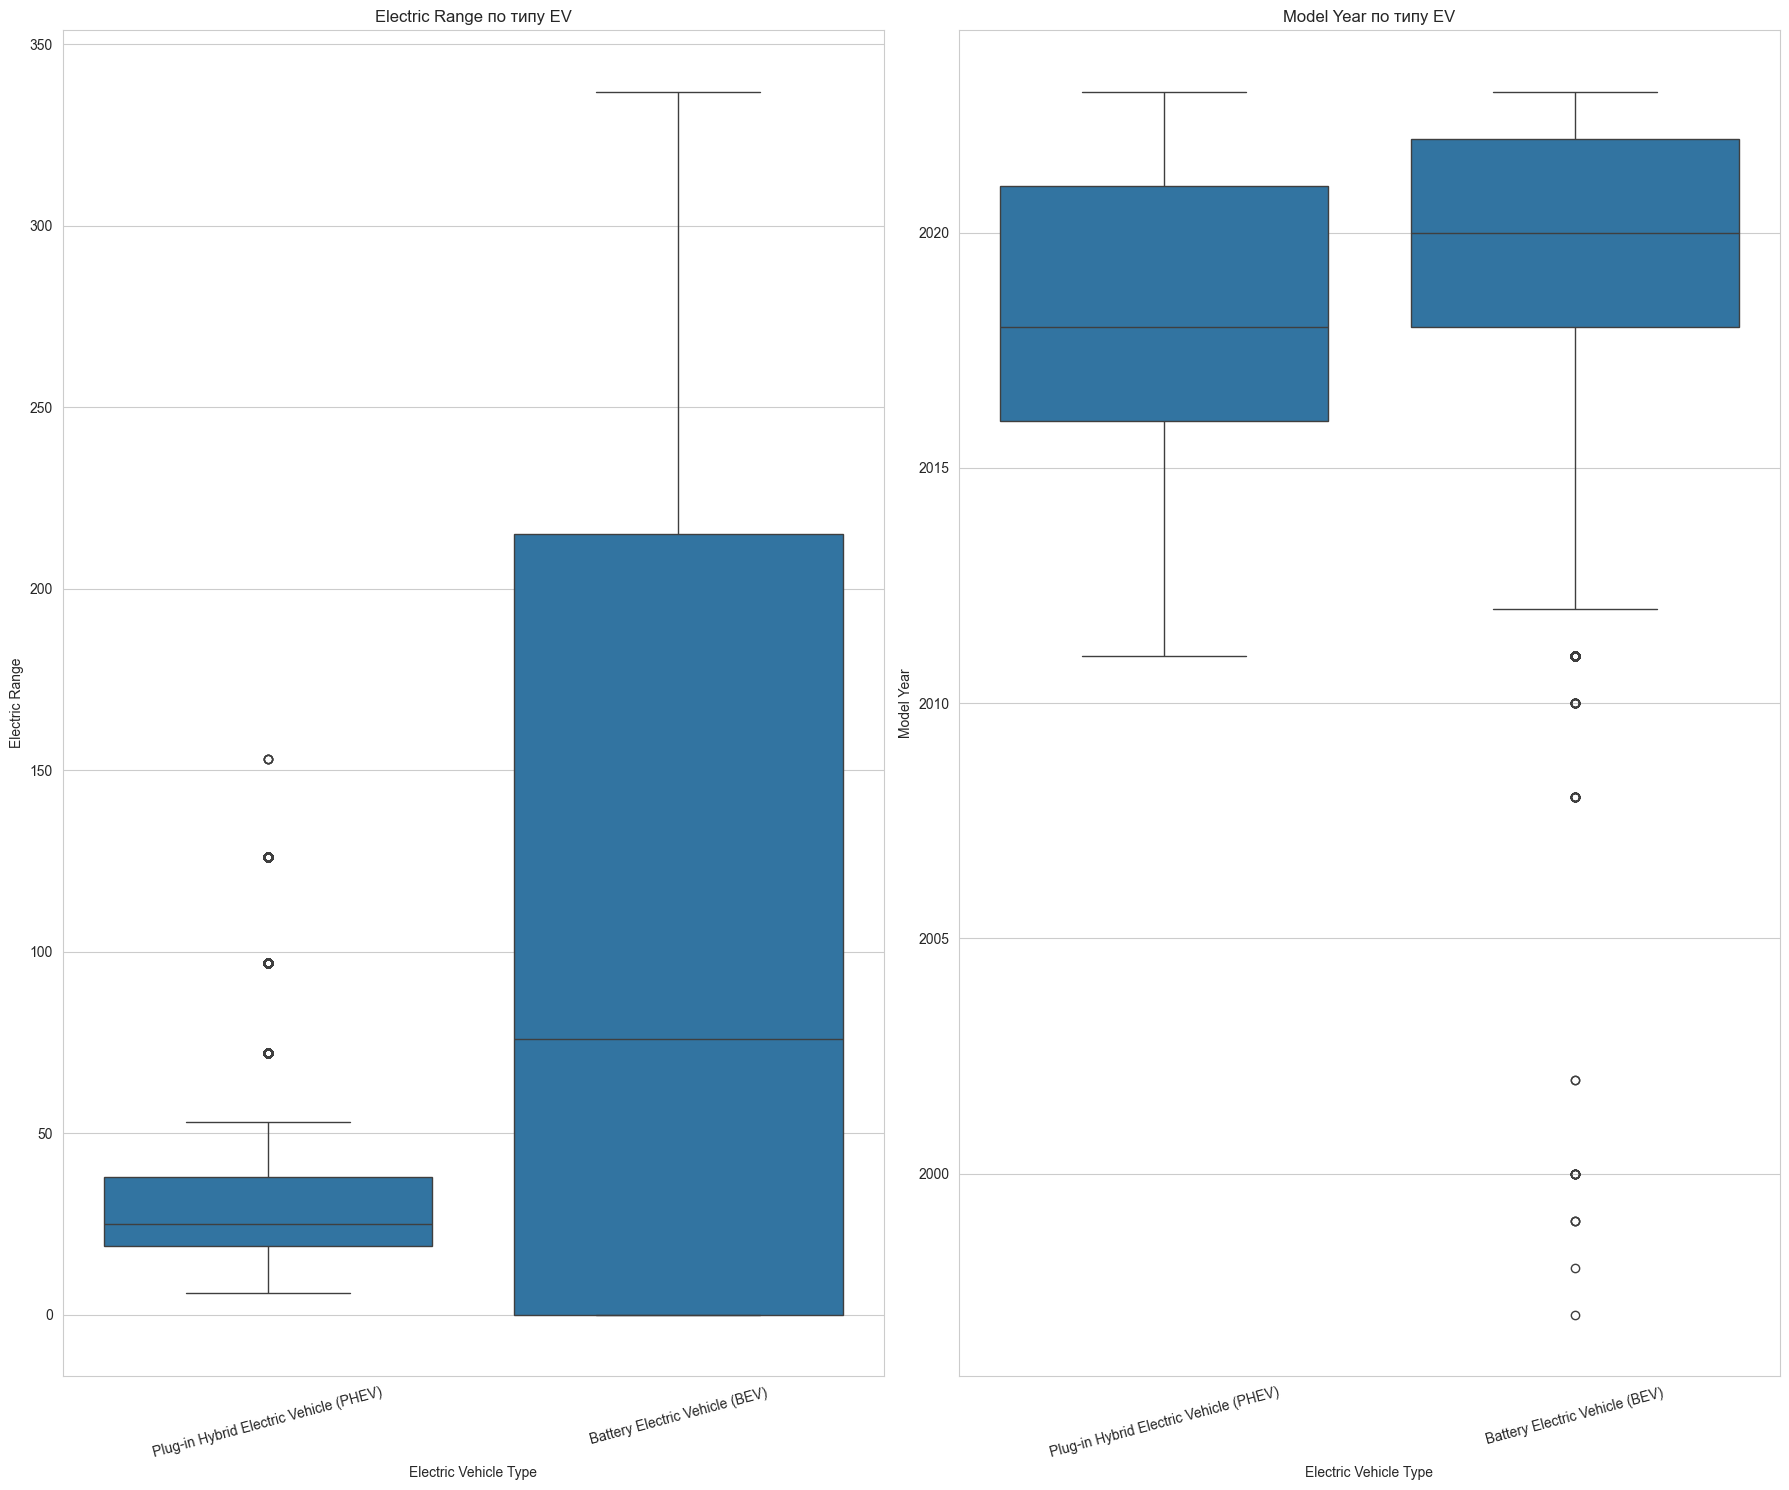

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(18, 15))

sns.boxplot(data=data, x='Electric Vehicle Type', y='Electric Range', ax=axes[0])
axes[0].set_title('Electric Range по типу EV')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=data, x='Electric Vehicle Type', y='Model Year', ax=axes[1])
axes[1].set_title('Model Year по типу EV')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Диаграмма рассеяния

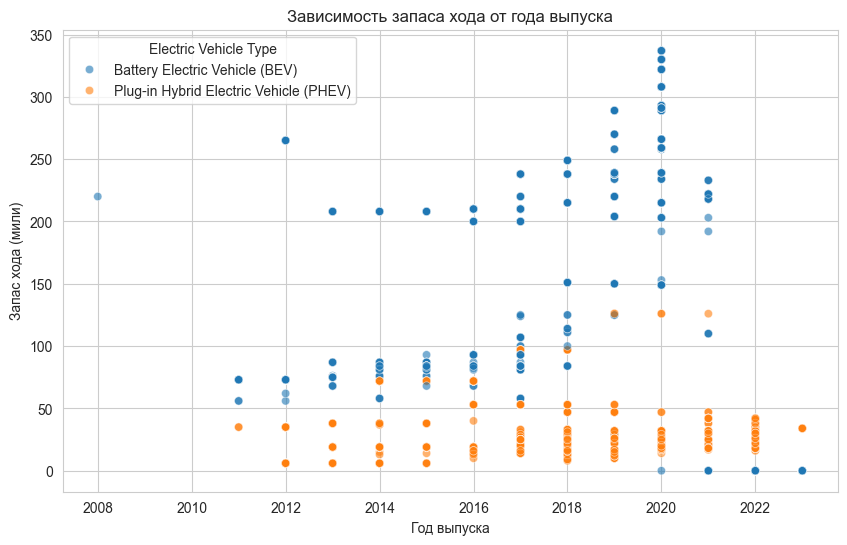

In [123]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data.sample(5000, random_state=42),
    x='Model Year', y='Electric Range',
    hue='Electric Vehicle Type',
    alpha=0.6
)
plt.title('Зависимость запаса хода от года выпуска')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()

Топ-10 марок и моделей

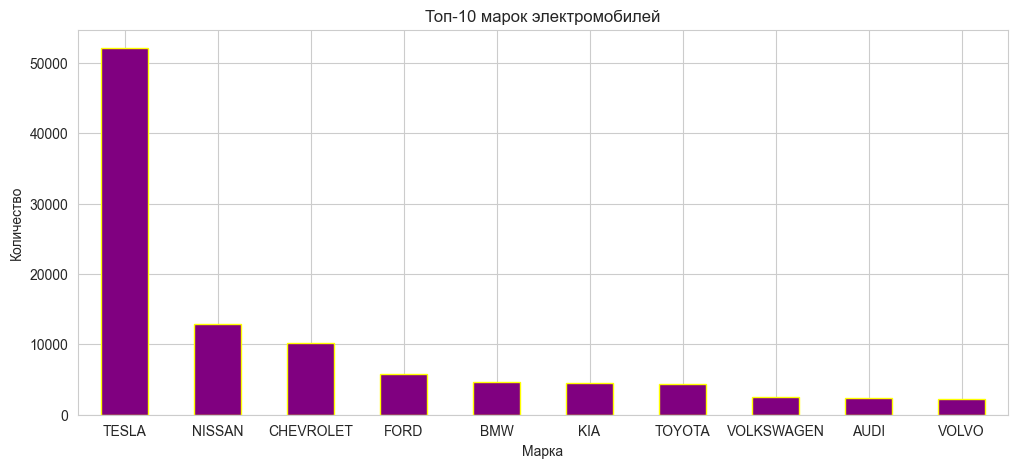

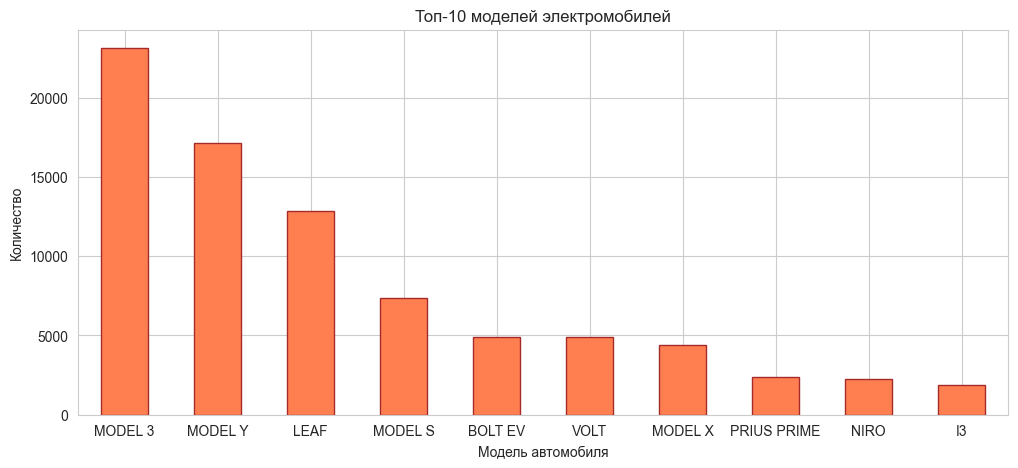

In [124]:
plt.figure(figsize=(12, 5))
data['Make'].value_counts().head(10).plot(kind='bar', color='purple', 
                                          edgecolor='yellow')
plt.title('Топ-10 марок электромобилей')
plt.xlabel('Марка')
plt.ylabel('Количество')
plt.xticks(rotation=360)

plt.figure(figsize=(12, 5))
data['Model'].value_counts().head(10).plot(kind='bar', color='coral',
                                            edgecolor='brown')
plt.title('Топ-10 моделей электромобилей')
plt.xlabel('Модель автомобиля')
plt.ylabel('Количество')
plt.xticks(rotation=360)
plt.show()

Очистка данных

Удаление лишних колонок

In [125]:
columns_to_drops = [
    'VIN (1-10)', #индефикатор - не несёт полезной информации
    'DOL Vehicle ID', #индефикатор тож самое
    'Vehicle Location', #Координаты машины - не зачем, бесполезная инфа
    '2020 Census Tract', #номер района - так же бесполезно
    'Base MSRP', #рекомендованная цена производителя - 99% нулей
    'State', #штат где почти всё WA - не несёт смысловой нагрузки
    'Model', #много уникальных
    'City', #много уникальных
    'Clean Alternative Fuel Vehicle (CAFV) Eligibility' #утечка данных
]
data_clean = data.drop(columns=columns_to_drops)

print("Было колонок: ", data.shape[1])
print("Стало колонок: ", data_clean.shape[1])
print('\n', data_clean.columns.tolist())

Было колонок:  17
Стало колонок:  8

 ['County', 'Postal Code', 'Model Year', 'Make', 'Electric Vehicle Type', 'Electric Range', 'Legislative District', 'Electric Utility']


Удаление пропусков

In [126]:
print("Пропуски до:")
print(data_clean.isnull().sum().sum(), "\n")
print(data_clean.isnull().sum(), "\n")

data_clean = data_clean.dropna()

print("Пропуски после: ")
print(data_clean.isnull().sum().sum())
print(data_clean.isnull().sum())
print("Строк осталось:", len(data_clean))

Пропуски до:
729 

County                     0
Postal Code                0
Model Year                 0
Make                       0
Electric Vehicle Type      0
Electric Range             0
Legislative District     286
Electric Utility         443
dtype: int64 

Пропуски после: 
0
County                   0
Postal Code              0
Model Year               0
Make                     0
Electric Vehicle Type    0
Electric Range           0
Legislative District     0
Electric Utility         0
dtype: int64
Строк осталось: 112191


Удаление дубликатов

In [127]:
print("Строк до: ", len(data_clean))

data_clean = data_clean.drop_duplicates()

print("Строк после: ", len(data_clean))
print("Удалено дубликатов: ", len(data) - len(data_clean))

Строк до:  112191
Строк после:  36433
Удалено дубликатов:  76201


Матрица корреляций

                      Postal Code  Model Year  Electric Range  \
Postal Code              1.000000   -0.016509        0.010640   
Model Year              -0.016509    1.000000       -0.145412   
Electric Range           0.010640   -0.145412        1.000000   
Legislative District    -0.496710    0.003029       -0.014991   

                      Legislative District  
Postal Code                      -0.496710  
Model Year                        0.003029  
Electric Range                   -0.014991  
Legislative District              1.000000  


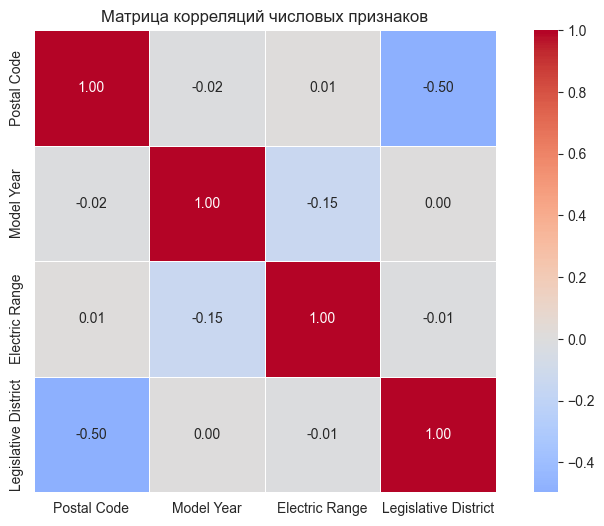

In [128]:
numeric_cols = data_clean.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = data_clean[numeric_cols].corr()

print(corr_matrix)

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Матрица корреляций числовых признаков')
plt.show()

Подготовка данных для кластеризации

In [129]:
from sklearn.preprocessing import StandardScaler

X = data_clean[['Make', 'Model Year', 'Electric Range']].copy()
y_true = data_clean['Electric Vehicle Type']

X = pd.get_dummies(X, columns=['Make'], drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Размер матрицы X для кластеризации: {X_scaled.shape}")
print(f"Первые 5 строк масштабированных данных:\n{X_scaled[:5]}")

Размер матрицы X для кластеризации: (36433, 35)
Первые 5 строк масштабированных данных:
[[-2.42271015 -0.12657653 -0.01386255 -0.00907467 -0.28981522 -0.05113065
  -0.36754661 -0.1577844  -0.12763445 -0.0222329  -0.29539827 -0.02029493
  -0.10851191 -0.16485953 -0.06826616 -0.14358962 -0.24993073 -0.03100954
  -0.02822438 -0.06536484 -0.03888319 -0.10575974 -0.11208116 -0.09905454
   2.91168124 -0.09516652 -0.13049202 -0.0859222  -0.08194243 -0.03707112
  -0.50639937 -0.00907467 -0.25540185 -0.17784466 -0.19804222]
 [-0.4565113   1.60611066 -0.01386255 -0.00907467 -0.28981522 -0.05113065
   2.7207434  -0.1577844  -0.12763445 -0.0222329  -0.29539827 -0.02029493
  -0.10851191 -0.16485953 -0.06826616 -0.14358962 -0.24993073 -0.03100954
  -0.02822438 -0.06536484 -0.03888319 -0.10575974 -0.11208116 -0.09905454
  -0.34344419 -0.09516652 -0.13049202 -0.0859222  -0.08194243 -0.03707112
  -0.50639937 -0.00907467 -0.25540185 -0.17784466 -0.19804222]
 [ 0.19888832 -0.62012985 -0.01386255 -0.00907

Метод локтя (Elbow Method):строим график зависимости внутрикластерного расстояния от количества кластеров

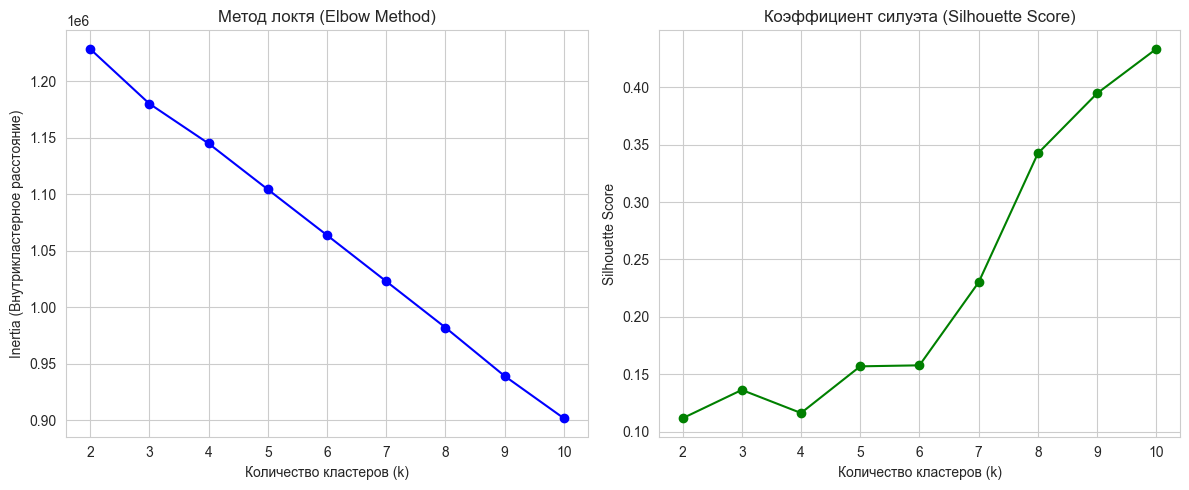

In [130]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Списки для сохранения результатов
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    
    #Сохраняем метрики
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

#Строим графики
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', color='blue')
plt.title('Метод локтя (Elbow Method)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Inertia (Внутрикластерное расстояние)')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='o', color='green')
plt.title('Коэффициент силуэта (Silhouette Score)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

Обучаем K-Means для k=2 и k=3

In [131]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_2.fit(X_scaled)
data_clean['Cluster_k2'] = kmeans_2.labels_

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_3.fit(X_scaled)
data_clean['Cluster_k3'] = kmeans_3.labels_

#Смотрим, как кластеры соотносятся с реальными классами
print("=== Сравнение для k=2 ===")
print(pd.crosstab(data_clean['Cluster_k2'], data_clean['Electric Vehicle Type']))

print("\n=== Сравнение для k=3 ===")
print(pd.crosstab(data_clean['Cluster_k3'], data_clean['Electric Vehicle Type']))

=== Сравнение для k=2 ===
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
Cluster_k2                                              
0                                               12850   
1                                                8649   

Electric Vehicle Type  Plug-in Hybrid Electric Vehicle (PHEV)  
Cluster_k2                                                     
0                                                        4920  
1                                                       10014  

=== Сравнение для k=3 ===
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
Cluster_k3                                              
0                                                8249   
1                                                5017   
2                                                8233   

Electric Vehicle Type  Plug-in Hybrid Electric Vehicle (PHEV)  
Cluster_k3                                                     
0                                               

Средние значения признаков по кластерам

In [132]:
print("Средние характеристики по кластерам (k=3):")
print(data_clean.groupby('Cluster_k3')[['Model Year', 'Electric Range']].mean())

#Посмотрим на топ-3 марки в каждом кластере
for cluster in [0, 1, 2]:
    print(f"\n--- Кластер {cluster} ---")
    print(data_clean[data_clean['Cluster_k3'] == cluster]['Make'].value_counts().head(3))
    print(f"Типы машин:\n{data_clean[data_clean['Cluster_k3'] == cluster]['Electric Vehicle Type'].value_counts()}")

Средние характеристики по кластерам (k=3):
             Model Year  Electric Range
Cluster_k3                             
0           2018.361096      174.859155
1           2016.816118       59.169026
2           2018.962083       54.232138

--- Кластер 0 ---
Make
TESLA    7436
FIAT      584
HONDA     424
Name: count, dtype: int64
Типы машин:
Electric Vehicle Type
Battery Electric Vehicle (BEV)            8249
Plug-in Hybrid Electric Vehicle (PHEV)     768
Name: count, dtype: int64

--- Кластер 1 ---
Make
NISSAN    3844
FORD      2924
SMART      243
Name: count, dtype: int64
Типы машин:
Electric Vehicle Type
Battery Electric Vehicle (BEV)            5017
Plug-in Hybrid Electric Vehicle (PHEV)    2118
Name: count, dtype: int64

--- Кластер 2 ---
Make
CHEVROLET    4335
BMW          2823
TOYOTA       2231
Name: count, dtype: int64
Типы машин:
Electric Vehicle Type
Plug-in Hybrid Electric Vehicle (PHEV)    12048
Battery Electric Vehicle (BEV)             8233
Name: count, dtype: int64


Визуализация K-Means (График рассеяния)

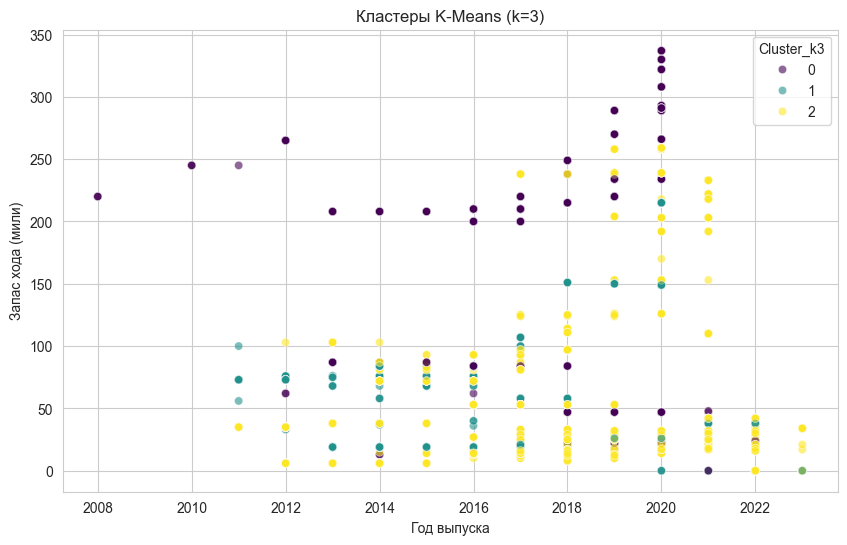

In [133]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data_clean.sample(5000, random_state=22),
    x='Model Year', y='Electric Range',
    hue='Cluster_k3',
    palette='viridis',
    alpha=0.6
)
plt.title('Кластеры K-Means (k=3)')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()

DBSCAN - подбираем значения eps и min_samples

In [ ]:
for eps_val in [10.0, 15.0]:
    dbscan = DBSCAN(eps=eps_val, min_samples=50)
    labels = dbscan.fit_predict(X_scaled)
        
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
        
    print(f"eps={eps_val}, min_samples={50}: Кластеров = {n_clusters}, Шум = {n_noise} ({n_noise/len(labels)*100:.1f}%)")

eps=10.0, min_samples=50: Кластеров = 10, Шум = 110 (0.3%)
eps=15.0, min_samples=50: Кластеров = 5, Шум = 110 (0.3%)


In [143]:
for eps_val in [0.5, 1.0, 1.5, 2.0, 2.5]:
    dbscan = DBSCAN(eps=eps_val, min_samples=20)
    labels = dbscan.fit_predict(X_scaled)
        
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
        
    print(f"eps={eps_val}, min_samples={20}: Кластеров = {n_clusters}, Шум = {n_noise} ({n_noise/len(labels)*100:.1f}%)")

eps=0.5, min_samples=20: Кластеров = 56, Шум = 129 (0.4%)
eps=1.0, min_samples=20: Кластеров = 38, Шум = 90 (0.2%)
eps=1.5, min_samples=20: Кластеров = 34, Шум = 80 (0.2%)
eps=2.0, min_samples=20: Кластеров = 31, Шум = 80 (0.2%)
eps=2.5, min_samples=20: Кластеров = 28, Шум = 61 (0.2%)


DBSCAN

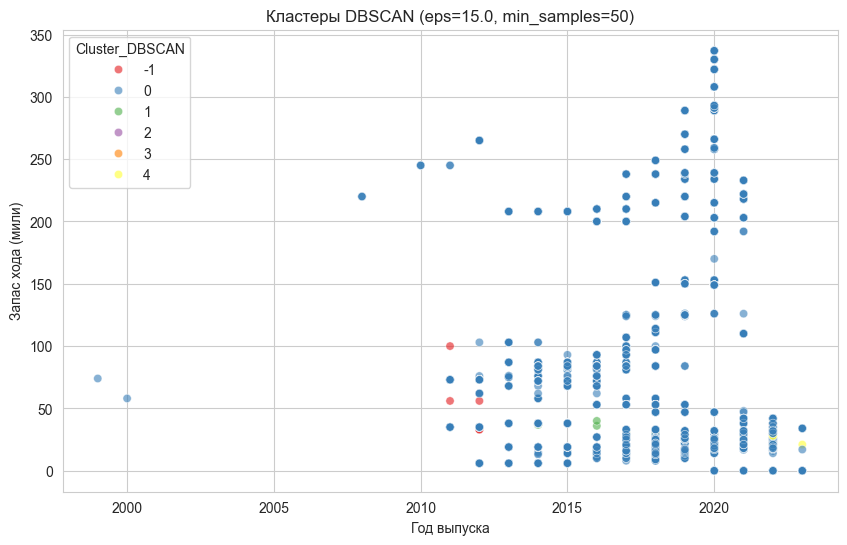

Средние характеристики по кластерам DBSCAN:
                 Model Year  Electric Range
Cluster_DBSCAN                             
0               2018.379476       85.852119
1               2015.505263       35.368421
2               2019.080000       16.660000
3               2022.000000        0.000000
4               2021.438710       22.941935


In [136]:
from sklearn.cluster import DBSCAN

#Обучаем DBSCAN с параметрами eps=15.0, min_samples=50
dbscan = DBSCAN(eps=15.0, min_samples=50)
data_clean['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data_clean.sample(5000, random_state=42),
    x='Model Year', y='Electric Range',
    hue='Cluster_DBSCAN',
    palette='Set1',
    alpha=0.6
)
plt.title('Кластеры DBSCAN (eps=15.0, min_samples=50)')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()

print("Средние характеристики по кластерам DBSCAN:")
print(data_clean[data_clean['Cluster_DBSCAN'] != -1].groupby('Cluster_DBSCAN')[['Model Year', 'Electric Range']].mean())

сравнение для DBSCAN (eps=15.0, min_samples=50)

In [137]:
print("\n\nСравнение DBSCAN с реальными классами (eps=15.0, min_samples=50):")
print(pd.crosstab(data_clean['Cluster_DBSCAN'], data_clean['Electric Vehicle Type']))



Сравнение DBSCAN с реальными классами (eps=15.0, min_samples=50):
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
Cluster_DBSCAN                                          
-1                                                 25   
 0                                              21418   
 1                                                  0   
 2                                                  1   
 3                                                 55   
 4                                                  0   

Electric Vehicle Type  Plug-in Hybrid Electric Vehicle (PHEV)  
Cluster_DBSCAN                                                 
-1                                                         85  
 0                                                      14550  
 1                                                         95  
 2                                                         49  
 3                                                          0  
 4                         

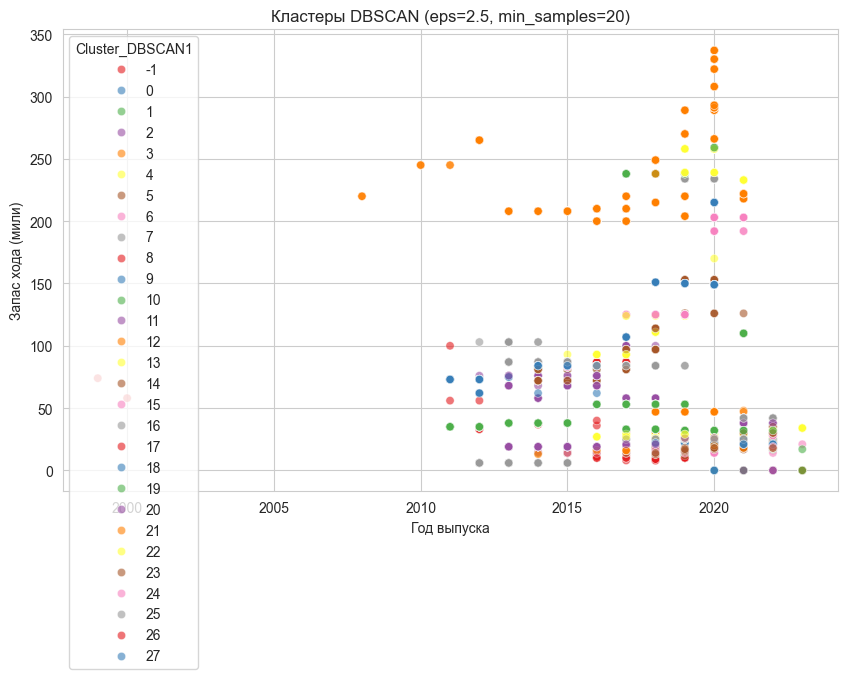

Средние характеристики по кластерам DBSCAN:
                  Model Year  Electric Range
Cluster_DBSCAN1                             
0                2016.650104       88.532258
1                2017.125490       95.151326
2                2017.312157       21.033997
3                2018.757365      176.365951
4                2019.773576       73.167134
5                2018.171095       48.635140
6                2019.227869       54.137705
7                2015.508562       85.515411
8                2015.505263       35.368421
9                2018.172316       28.901130
10               2019.605650       32.355932
11               2022.000000        0.000000
12               2018.495283       46.287736
13               2020.751037       56.352697
14               2020.216000       15.284364
15               2019.453894       49.647269
16               2017.726335       25.472409
17               2018.774194       25.198511
18               2021.472826       22.675272
19         

In [138]:
from sklearn.cluster import DBSCAN

#Обучаем DBSCAN с удачными параметрами
dbscan = DBSCAN(eps=2.5, min_samples=20)
data_clean['Cluster_DBSCAN1'] = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data_clean.sample(5000, random_state=42),
    x='Model Year', y='Electric Range',
    hue='Cluster_DBSCAN1',
    palette='Set1',
    alpha=0.6
)
plt.title('Кластеры DBSCAN (eps=2.5, min_samples=20)')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()

print("Средние характеристики по кластерам DBSCAN:")
print(data_clean[data_clean['Cluster_DBSCAN1'] != -1].groupby('Cluster_DBSCAN1')[['Model Year', 'Electric Range']].mean())

Сравнение DBSCAN (eps=2.5, min_samples=20)

In [139]:
print("\n\nСравнение DBSCAN с реальными классами (eps=2.5, min_samples=20):")
print(pd.crosstab(data_clean['Cluster_DBSCAN1'], data_clean['Electric Vehicle Type']))



Сравнение DBSCAN с реальными классами (eps=2.5, min_samples=20):
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
Cluster_DBSCAN1                                         
-1                                                 40   
 0                                               3844   
 1                                               2126   
 2                                                907   
 3                                               8037   
 4                                               1289   
 5                                                606   
 6                                                274   
 7                                                584   
 8                                                  0   
 9                                                 59   
 10                                                 0   
 11                                               267   
 12                                                 0   
 13                  

Иерархическая кластеризация и дендрограмма

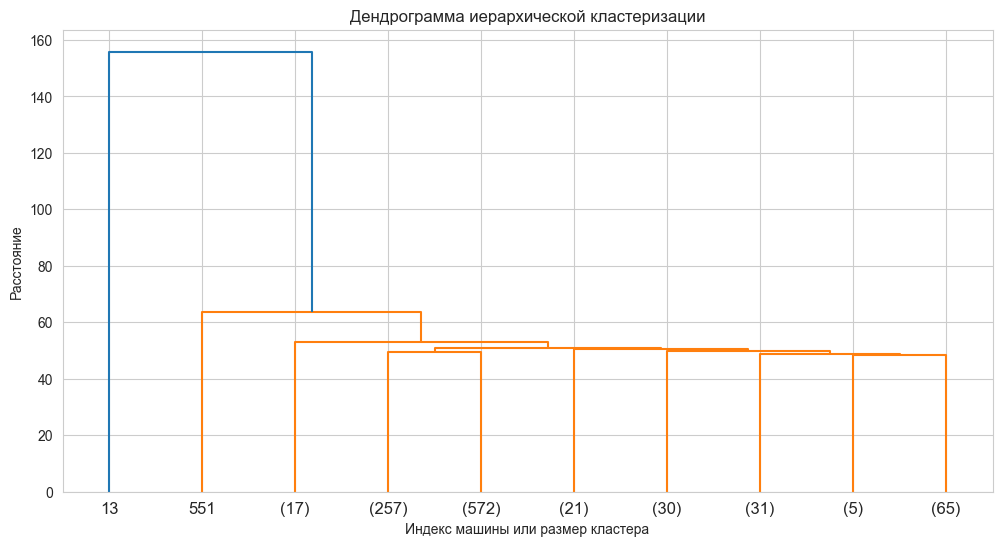

In [140]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

#Строим дендрограмму (дерево) на выборке из 1000 машин, чтобы не тормозило
sample_idx = np.random.choice(len(X_scaled), 1000, replace=False)
X_sample = X_scaled[sample_idx]

plt.figure(figsize=(12, 6))
linked = linkage(X_sample, method='ward')
dendrogram(linked, truncate_mode='lastp', p=10)
plt.title('Дендрограмма иерархической кластеризации')
plt.xlabel('Индекс машины или размер кластера')
plt.ylabel('Расстояние')
plt.show()

Обучаем модель на 2 кластера

In [141]:
hc = AgglomerativeClustering(n_clusters=2)
data_clean['Cluster_HC'] = hc.fit_predict(X_scaled)

#Сравнение с реальными классами
print("Сравнение с реальными классами (Иерархическая кластеризация):")
print(pd.crosstab(data_clean['Cluster_HC'], data_clean['Electric Vehicle Type']))

Сравнение с реальными классами (Иерархическая кластеризация):
Electric Vehicle Type  Battery Electric Vehicle (BEV)  \
Cluster_HC                                              
0                                               13293   
1                                                8206   

Electric Vehicle Type  Plug-in Hybrid Electric Vehicle (PHEV)  
Cluster_HC                                                     
0                                                       14213  
1                                                         721  


Визуализация иерархической кластеризации

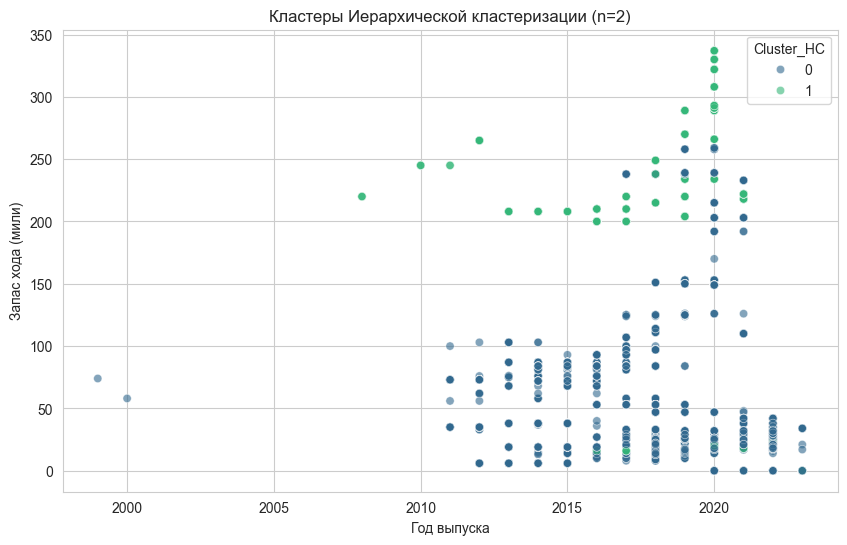

In [142]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data_clean.sample(5000, random_state=42),
    x='Model Year', y='Electric Range',
    hue='Cluster_HC',
    palette='viridis',
    alpha=0.6
)
plt.title('Кластеры Иерархической кластеризации (n=2)')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()